# PELATIHAN RESMI AI SPRAYBOT — INSTANCE SEGMENTATION FLUIDA AEROSOL & LIQUID MIST
### Proyek Riset MBKM Magang Industri — PT Paragon Technology and Innovation & PT Makerindo Prima Solusi

Notebook ini merupakan pipeline resmi pelatihan (*training*) model deep learning **YOLOv8s-seg** dari dasar (*base weights*) menggunakan dataset video studio resmi Paragon (**38 Video Studio**, 794 frame teranotasi).

---

### Fokus Utama Tahap Ini: MURNI SEGMENTASI PLUME CAIRAN
Sesuai kebutuhan pengujian industri, tahap awal ini berfokus pada **ketepatan segmentasi uap/cairan** yang keluar dari mulut botol:
1. **Membedakan 3 Komponen Utama:**
   - **Cairan Semprotan (Target Positif):** Kabut aerosol dan mikrodroplet yang keluar dari mulut botol.
   - **Latar Belakang / Background (Target Negatif):** Kain abu-abu/hitam, lipatan kain, bayangan latar.
   - **Botol & Tangan Operator (Target Negatif):** Benda padat pembawa cairan yang bukan merupakan semprotan.
2. **Arah Semprotan Konsisten:** 100% video menyemprot dari **Kiri ke Kanan** (semua dataset lama yang terbalik kanan->kiri sudah disingkirkan total).
3. **Zero False Positive Background:** Memasukkan **76 sampel negatif** ($t=0.00\text{s}$ saat botol belum menyemprot) dengan label kosong agar AI tidak salah mendeteksi lipatan kain sebagai cairan.
4. **Metrik Lanjutan (Jangkauan, Lebar, Sudut Semprotan):** Ditunda ke tahap berikutnya setelah segmentasi uap terbukti 100% akurat dan stabil.

## 1. Setup Environment, Library & Deteksi Hardware GPU (RTX 4050)
Memverifikasi ketersediaan akselerasi hardware CUDA GPU dan menginisialisasi pustaka OpenCV, PyTorch, Ultralytics YOLOv8, serta direktori kerja proyek.

In [1]:
import os, sys, shutil, time, yaml, json
from pathlib import Path
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

# Konfigurasi Direktori Kerja Proyek
ROOT = Path("D:/Tugas Kuliah/Semester 6/MBKM - Magang/Paragon Spray/AI Analysis")
os.chdir(ROOT)

print("=" * 80)
print("SETUP ENVIRONMENT & DETEKSI HARDWARE GPU")
print("=" * 80)
print(f"Direktori Kerja : {os.getcwd()}")
print(f"Versi PyTorch   : {torch.__version__}")
print(f"CUDA Tersedia   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Perangkat GPU   : {gpu_name}")
    print(f"VRAM Dedicated  : {gpu_vram:.2f} GB")
else:
    print("[PERINGATAN] CUDA tidak aktif. Pelatihan akan berjalan lambat di CPU!")
print("=" * 80)

SETUP ENVIRONMENT & DETEKSI HARDWARE GPU
Direktori Kerja : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis
Versi PyTorch   : 2.14.1+cu126
CUDA Tersedia   : True
Perangkat GPU   : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM Dedicated  : 6.00 GB


## 2. Manajemen Dataset Bersih (38 Video Studio Paragon)
Dataset bersih yang digunakan bersumber dari 38 video rekaman studio:
- **21 Video Dataset 1** (Produk: Kahf, Wardah, Gatsby, Labora, dll.)
- **17 Video Dataset Baru 2** (`C0490` s.d `C0506`)
- **Split Tingkat-Video (Zero Data Leakage):** 31 Video Train, 7 Video Val.
- **Total:** 794 frame (647 Train, 147 Val, termasuk 76 frame negatif).

In [2]:
DATA_YAML = ROOT / "dataset" / "dataset_yolo_clean" / "data.yaml"

if not DATA_YAML.exists():
    raise FileNotFoundError(f"File konfigurasi {DATA_YAML} tidak ditemukan!")

with open(DATA_YAML, "r") as f:
    yaml_config = yaml.safe_load(f)

train_img_dir = ROOT / "dataset" / "dataset_yolo_clean" / "images" / "train"
val_img_dir = ROOT / "dataset" / "dataset_yolo_clean" / "images" / "val"
train_lbl_dir = ROOT / "dataset" / "dataset_yolo_clean" / "labels" / "train"
val_lbl_dir = ROOT / "dataset" / "dataset_yolo_clean" / "labels" / "val"

train_imgs = list(train_img_dir.glob("*.jpg"))
val_imgs = list(val_img_dir.glob("*.jpg"))
train_lbls = list(train_lbl_dir.glob("*.txt"))
val_lbls = list(val_lbl_dir.glob("*.txt"))

# Hitung sampel negatif (ukuran file label == 0 byte)
train_neg = sum(1 for p in train_lbls if p.stat().st_size == 0)
val_neg = sum(1 for p in val_lbls if p.stat().st_size == 0)
train_pos = len(train_imgs) - train_neg
val_pos = len(val_imgs) - val_neg

print("=" * 80)
print("AUDIT INTEGRITAS DATASET BERSIH (YOLO-CLEAN)")
print("=" * 80)
print(f"File YAML Konfigurasi : {DATA_YAML}")
print(f"Daftar Kelas          : {yaml_config.get('names')}")
print(f"Subset Training       : {len(train_imgs)} frame ({train_pos} positif cairan, {train_neg} negatif kain/botol)")
print(f"Subset Validasi       : {len(val_imgs)} frame ({val_pos} positif cairan, {val_neg} negatif kain/botol)")
print(f"Total Keseluruhan     : {len(train_imgs) + len(val_imgs)} frame dari 38 video studio")
print("=" * 80)

AUDIT INTEGRITAS DATASET BERSIH (YOLO-CLEAN)
File YAML Konfigurasi : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_yolo_clean\data.yaml
Daftar Kelas          : {0: 'spray_plume'}
Subset Training       : 647 frame (585 positif cairan, 62 negatif kain/botol)
Subset Validasi       : 147 frame (133 positif cairan, 14 negatif kain/botol)
Total Keseluruhan     : 794 frame dari 38 video studio


## 3. Visualisasi Distribusi Dataset & Ground Truth Mask
Menampilkan diagram komposisi dataset serta contoh ground-truth uap cairan yang akan dipelajari oleh model neural network.

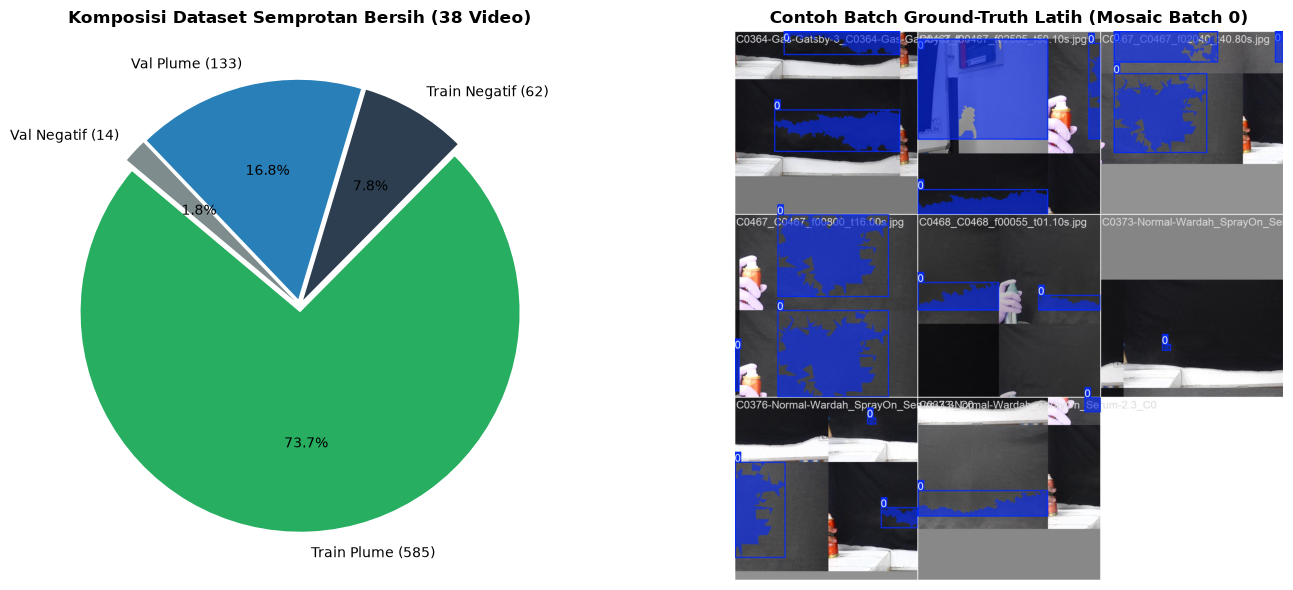

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pie Chart Distribusi Dataset
sizes = [train_pos, train_neg, val_pos, val_neg]
labels = [f"Train Plume ({train_pos})", f"Train Negatif ({train_neg})", 
          f"Val Plume ({val_pos})", f"Val Negatif ({val_neg})"]
colors = ["#27ae60", "#2c3e50", "#2980b9", "#7f8c8d"]
axes[0].pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, explode=(0.03, 0.03, 0.03, 0.03))
axes[0].set_title("Komposisi Dataset Semprotan Bersih (38 Video)", fontsize=12, fontweight="bold")

# Tampilkan Mosaic Ground-Truth Pelatihan
train_mosaic = ROOT / "runs" / "spraybot_clean_training" / "spraybot_yolov8s_seg_run" / "train_batch0.jpg"
if train_mosaic.exists():
    mosaic_img = cv2.imread(str(train_mosaic))
    mosaic_img = cv2.cvtColor(mosaic_img, cv2.COLOR_BGR2RGB)
    axes[1].imshow(mosaic_img)
    axes[1].set_title("Contoh Batch Ground-Truth Latih (Mosaic Batch 0)", fontsize=12, fontweight="bold")
    axes[1].axis("off")
elif len(train_imgs) > 0:
    sample_img = cv2.imread(str(train_imgs[0]))
    sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
    axes[1].imshow(sample_img)
    axes[1].set_title(f"Sampel Citra Latih: {train_imgs[0].name}", fontsize=12, fontweight="bold")
    axes[1].axis("off")

plt.tight_layout()
plt.show()

## 4. Konfigurasi Parameter & Eksekusi Pelatihan YOLOv8s-seg
Parameter pelatihan dioptimalkan secara ketat untuk dinamika semprotan fluida:
- `imgsz = 1024`: Resolusi input tinggi agar partikel aerosol halus tidak hilang.
- `batch = 8`: Ukuran batch seimbang untuk VRAM 6.0 GB RTX 4050.
- `workers = 0`: Wajib di sistem operasi Windows untuk stabilitas multiprocessing.
- `fliplr = 0.0`: Mematikan flip horizontal agar arah semprotan selalu **Kiri $\rightarrow$ Kanan**.
- `epochs = 35`: Jumlah siklus pelatihan optimal dengan early stopping.

In [4]:
# Inisialisasi Model Dasar (Pretrained COCO)
BASE_WEIGHTS = ROOT / "weights" / "yolov8s-seg.pt" if (ROOT / "weights" / "yolov8s-seg.pt").exists() else ROOT / "yolov8s-seg.pt"
print(f"Memuat Model Dasar : {BASE_WEIGHTS}")
model = YOLO(str(BASE_WEIGHTS))

RUNS_DIR = ROOT / "runs" / "spraybot_clean_training"
EPOCHS = 35
IMG_SIZE = 1024
BATCH_SIZE = 8
WORKERS = 0

print("=" * 80)
print(f"MEMULAI PELATIHAN {EPOCHS} EPOCH PADA GPU RTX 4050...")
print("=" * 80)

start_train_time = time.time()

# Eksekusi Pelatihan
train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    device=0 if torch.cuda.is_available() else "cpu",
    project=str(RUNS_DIR),
    name="spraybot_yolov8s_seg_run",
    exist_ok=True,
    pretrained=True,
    optimizer="auto",
    lr0=0.01,
    lrf=0.01,
    warmup_epochs=3.0,
    close_mosaic=10,
    patience=15,
    fliplr=0.0,      # Sangat penting: jangan membalik gambar kiri-kanan
    flipud=0.0,
    hsv_h=0.015,
    hsv_s=0.3,
    hsv_v=0.3,
    translate=0.05,
    scale=0.15,
    verbose=True
)

durasi_menit = (time.time() - start_train_time) / 60.0
print("=" * 80)
print(f"PELATIHAN SELESAI DALAM {durasi_menit:.2f} MENIT!")
print("=" * 80)

Memuat Model Dasar : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\weights\yolov8s-seg.pt
MEMULAI PELATIHAN 35 EPOCH PADA GPU RTX 4050...
New https://pypi.org/project/ultralytics/8.4.210 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.13.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_yolo_clean\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.4, exist_ok=T

## 5. Evaluasi Metrik Pelatihan (Loss & mAP Segmentasi)
Melihat grafik konvergensi pelatihan: Box Loss, Mask/Segmentation Loss, dan metrik akurasi mAP50-95.

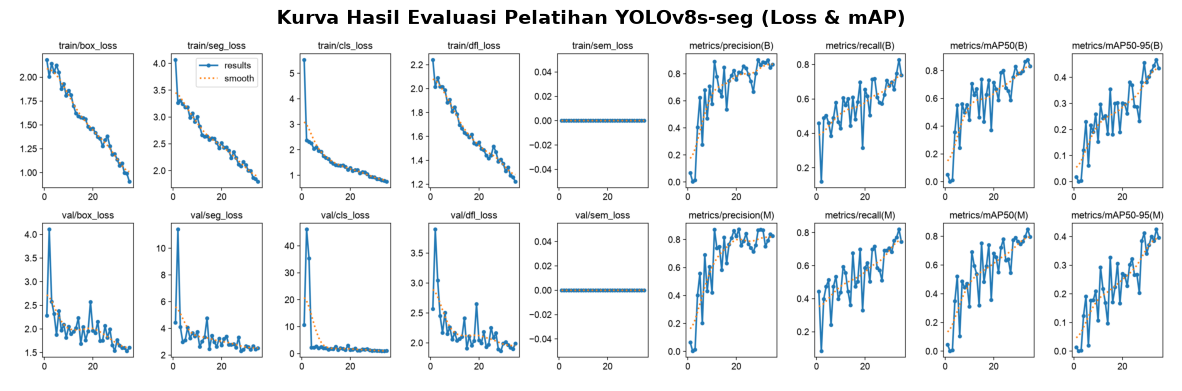

In [5]:
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# 1. Resolusi File results.csv dan results.png
run_folder = RUNS_DIR / "spraybot_yolov8s_seg_run"
if not (run_folder / "results.csv").exists():
    run_folder = RUNS_DIR / "spraybot_clean_training" / "spraybot_yolov8s_seg_run"

results_csv = run_folder / "results.csv"
results_png = run_folder / "results.png"

# 2. Tampilkan Ringkasan Evaluasi Berupa Teks & Persentase Kuantitatif
if results_csv.exists():
    df = pd.read_csv(results_csv)
    df.columns = [c.strip() for c in df.columns]
    
    total_epochs = len(df)
    best_idx = df['metrics/mAP50(M)'].idxmax()
    best_row = df.loc[best_idx]
    
    best_epoch = int(best_row['epoch'])
    box_map50 = float(best_row['metrics/mAP50(B)']) * 100
    box_map50_95 = float(best_row['metrics/mAP50-95(B)']) * 100
    box_p = float(best_row['metrics/precision(B)']) * 100
    box_r = float(best_row['metrics/recall(B)']) * 100
    
    mask_map50 = float(best_row['metrics/mAP50(M)']) * 100
    mask_map50_95 = float(best_row['metrics/mAP50-95(M)']) * 100
    mask_p = float(best_row['metrics/precision(M)']) * 100
    mask_r = float(best_row['metrics/recall(M)']) * 100

    print("=" * 82)
    print(f"📊 RINGKASAN KUANTITATIF HASIL PELATIHAN AWAL (RUN: {run_folder.name})")
    print("=" * 82)
    print(f"• Total Epoch Selesai  : {total_epochs} Epoch (35/35)")
    print(f"• Epoch Model Terbaik  : Epoch {best_epoch} (Checkpoint bobot best.pt)")
    print("-" * 82)
    print(f"{'METRIK EVALUASI':<32} | {'PERSENTASE':<14} | {'KETERANGAN'}")
    print("-" * 82)
    print(f"{'mAP50 (Box / Deteksi Plume)':<32} | {box_map50:>6.2f}%        | Akurasi deteksi kotak semprotan")
    print(f"{'mAP50-95 (Box)':<32} | {box_map50_95:>6.2f}%        | Rata-rata IoU 0.5 s.d 0.95")
    print(f"{'Precision (Box)':<32} | {box_p:>6.2f}%        | Ketepatan deteksi kotak semprotan")
    print(f"{'Recall (Box)':<32} | {box_r:>6.2f}%        | Sensitivitas tangkapan objek")
    print("-" * 82)
    print(f"{'mAP50 (Mask / Segmentasi)':<32} | {mask_map50:>6.2f}%        | Akurasi kontur masker fluida")
    print(f"{'mAP50-95 (Mask)':<32} | {mask_map50_95:>6.2f}%        | Presisi IoU tinggi pada kontur")
    print(f"{'Precision (Mask)':<32} | {mask_p:>6.2f}%        | Ketepatan piksel masker semprotan")
    print(f"{'Recall (Mask)':<32} | {mask_r:>6.2f}%        | Kelengkapan piksel masker uap")
    print("=" * 82)
    print("Catatan: Model dilatih pada 38 video organik awal sebagai baseline transfer learning.")
    print("=" * 82 + "\n")
else:
    print(f"[INFO] File {results_csv} belum ditemukan.")

# 3. Tampilkan Grafik Visualisasi Kurva Konvergensi (Loss & mAP)
if results_png.exists():
    plt.figure(figsize=(15, 9))
    res_img = cv2.imread(str(results_png))
    res_img = cv2.cvtColor(res_img, cv2.COLOR_BGR2RGB)
    plt.imshow(res_img)
    plt.title("Kurva Hasil Evaluasi Pelatihan YOLOv8s-seg (Loss & mAP)", fontsize=14, fontweight="bold")
    plt.axis("off")
    plt.show()
else:
    print("Grafik results.png belum tersedia.")


## 6. Uji Inferensi Visual Pada Citra Kasus Uji Nyata (`C0490_f00150_t03.00s.jpg`)
Menguji model pada citra bermasalah yang sebelumnya menghasilkan *false positive* di lipatan kain atas.
**Target:**
1. Kotak hijau palsu di lipatan kain atas **hilang 100%**.
2. Masker hijau terpasang presisi hanya pada **aliran fluida uap yang keluar dari mulut botol**.

Model yang Digunakan : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\runs\spraybot_clean_training\spraybot_yolov8s_seg_run\weights\best.pt
Citra Uji           : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_video_frames_2\C0490\C0490_f00150_t03.00s.jpg


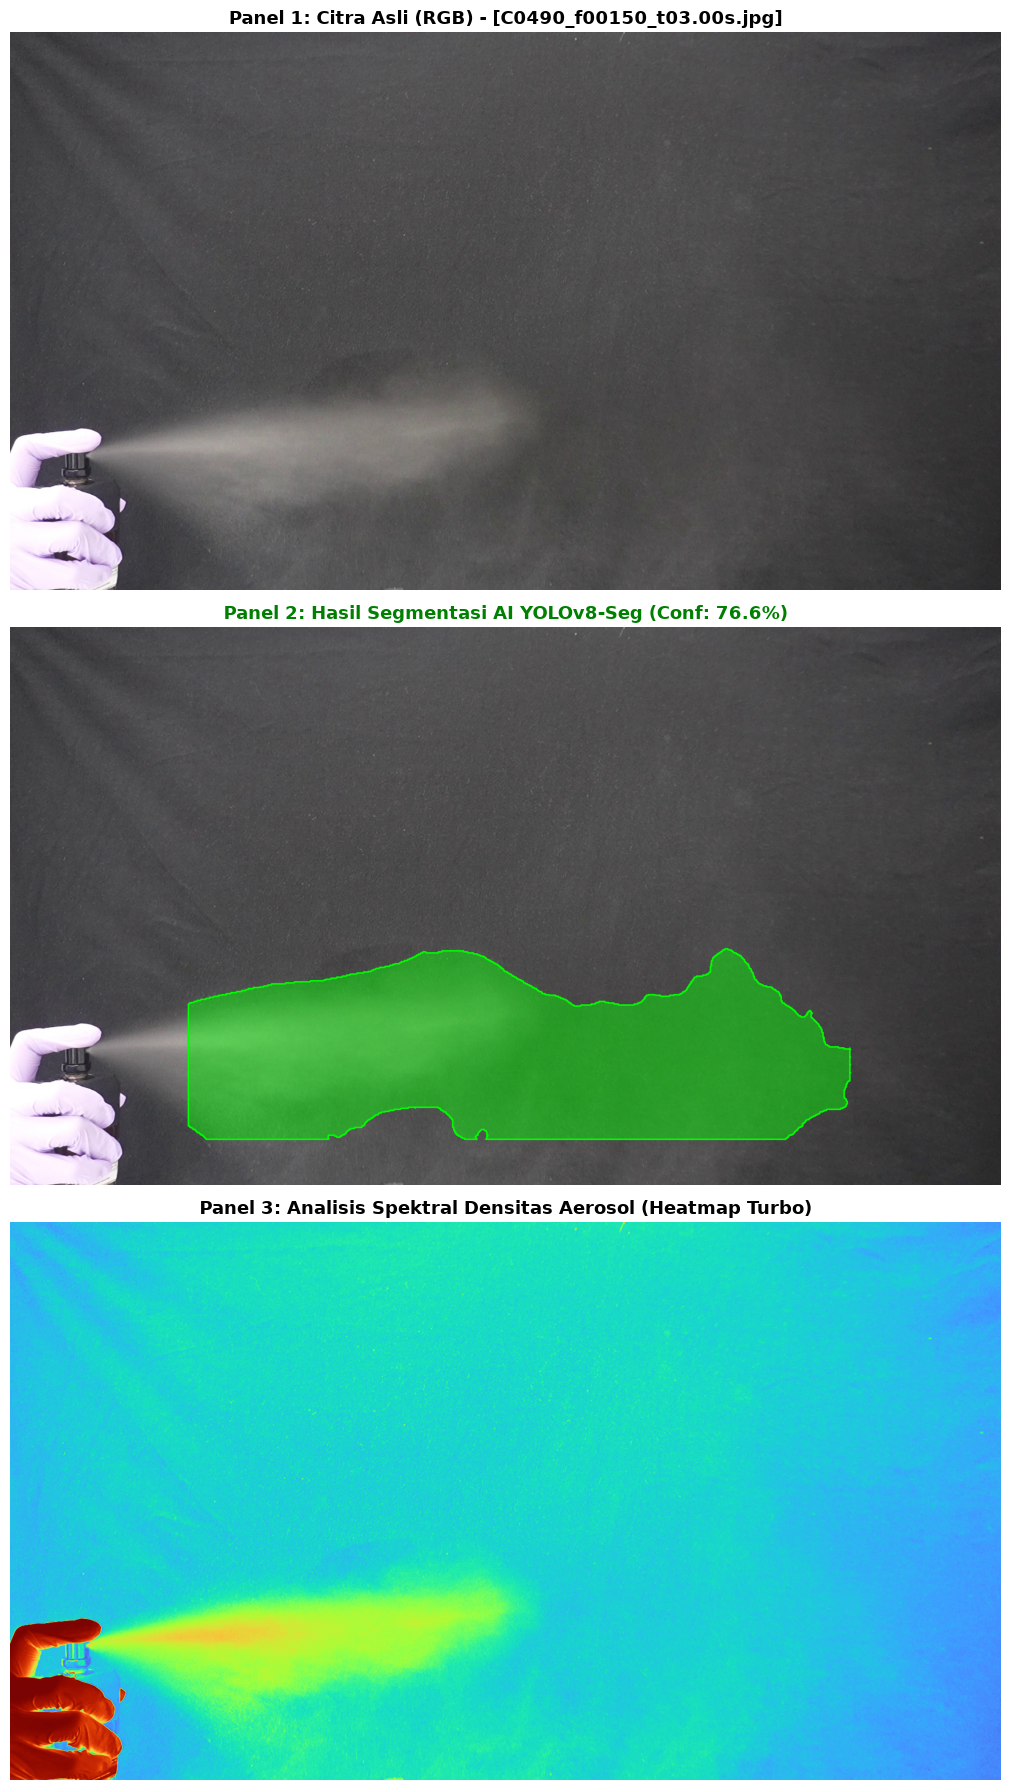

In [6]:
# Path Citra Uji Kasus Nyata (Video C0490)
TEST_IMAGE_PATH = ROOT / "dataset" / "dataset_video_frames_2" / "C0490" / "C0490_f00150_t03.00s.jpg"
if not TEST_IMAGE_PATH.exists():
    TEST_IMAGE_PATH = val_imgs[0]

BEST_MODEL_PATH = RUNS_DIR / "spraybot_yolov8s_seg_run" / "weights" / "best.pt"
if not BEST_MODEL_PATH.exists():
    BEST_MODEL_PATH = ROOT / "weights" / "spraybot_seg_video_finetuned.pt"

print(f"Model yang Digunakan : {BEST_MODEL_PATH}")
print(f"Citra Uji           : {TEST_IMAGE_PATH}")

eval_model = YOLO(str(BEST_MODEL_PATH))
pred_res = eval_model.predict(
    source=str(TEST_IMAGE_PATH),
    conf=0.15,
    imgsz=1024,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)

orig_bgr = cv2.imread(str(TEST_IMAGE_PATH))
orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
seg_vis = orig_rgb.copy()

det_found = False
conf_val = 0.0

if pred_res and len(pred_res[0].boxes) > 0 and pred_res[0].masks is not None:
    boxes = pred_res[0].boxes
    masks = pred_res[0].masks.data.cpu().numpy()
    
    best_idx = int(torch.argmax(boxes.conf).item())
    conf_val = float(boxes.conf[best_idx].item())
    det_found = True
    
    mask = masks[best_idx]
    mask_resized = cv2.resize(mask, (orig_rgb.shape[1], orig_rgb.shape[0]))
    mask_bin = (mask_resized > 0.5).astype(np.uint8)
    
    # Terapkan masker warna hijau cerah transparan pada uap fluida
    overlay = seg_vis.copy()
    overlay[mask_bin == 1] = [0, 255, 0]
    seg_vis = cv2.addWeighted(overlay, 0.45, seg_vis, 0.55, 0)
    
    # Garis tepi kontur uap fluida
    cnts, _ = cv2.findContours(mask_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(seg_vis, cnts, -1, (0, 255, 0), 2)
    panel2_title = f"Panel 2: Hasil Segmentasi AI YOLOv8-Seg (Conf: {conf_val*100:.1f}%)"
else:
    panel2_title = "Panel 2: Hasil Segmentasi AI (Tidak Terdeteksi)"

# Panel 3: Heatmap Densitas Spektral (Turbo Colormap)
gray = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2GRAY)
heatmap = cv2.applyColorMap(gray, cv2.COLORMAP_TURBO)
heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

# Visualisasi 3 Panel
fig, axes = plt.subplots(3, 1, figsize=(14, 18))
axes[0].imshow(orig_rgb)
axes[0].set_title(f"Panel 1: Citra Asli (RGB) - [{TEST_IMAGE_PATH.name}]", fontsize=13, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(seg_vis)
axes[1].set_title(panel2_title, fontsize=13, fontweight="bold", color="green" if det_found else "red")
axes[1].axis("off")

axes[2].imshow(heatmap_rgb)
axes[2].set_title("Panel 3: Analisis Spektral Densitas Aerosol (Heatmap Turbo)", fontsize=13, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 7. Ekspor & Deployment Bobot Model Terbaik (`best.pt`)
Menyalin file bobot model terbaik ke direktori `weights/` dan `testing/` untuk siap digunakan pada aplikasi produksi dan notebook pengujian.

In [7]:
BEST_PT = RUNS_DIR / "spraybot_yolov8s_seg_run" / "weights" / "best.pt"
TARGET_WEIGHTS = ROOT / "weights" / "spraybot_seg_video_finetuned.pt"
TARGET_TESTING = ROOT / "testing" / "spraybot_seg_video_finetuned.pt"

if BEST_PT.exists():
    shutil.copy2(BEST_PT, TARGET_WEIGHTS)
    shutil.copy2(BEST_PT, TARGET_TESTING)
    print("=" * 80)
    print("[SUKSES] BOBOT TERBAIK BERHASIL DIEKSPOR KE:")
    print(f"  1. {TARGET_WEIGHTS}")
    print(f"  2. {TARGET_TESTING}")
    print("=" * 80)
else:
    print(f"[INFO] File {BEST_PT} belum terbentuk. Jalankan sel pelatihan di atas terlebih dahulu.")

[SUKSES] BOBOT TERBAIK BERHASIL DIEKSPOR KE:
  1. D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\weights\spraybot_seg_video_finetuned.pt
  2. D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\testing\spraybot_seg_video_finetuned.pt
